# Expérience 4 — auto-encodeur variationnel sur CAMUS (RTX 4060 Ti)

Ce notebook reconstruit des coupes d'échocardiographie 2D (jeu CAMUS, images `camus_64`) avec un `AutoencoderKL` de MONAI. Il reprend la graine, le découpage par patient et la normalisation des expériences 1, 2 et 3, et change le protocole pour viser en même temps la fidélité de l'expérience 2, la structure de l'expérience 3 et un axe latent réellement aligné sur l'aire du ventricule gauche.

Quatre leviers sont nouveaux :

1. **GPU.** L'entraînement tourne sur la GeForce RTX 4060 Ti (CUDA), 80 époques.
2. **Capacité.** Canaux `(32, 64, 128, 128)`, comme l'expérience 2, avec deux blocs résiduels par échelle.
3. **Reconstruction tri-hybride.** MSE pondérée sur le cœur, L1 pondérée et SSIM, avec un β de KL très faible.
4. **AR-VAE à γ = 0,05.** La moyenne spatiale du premier canal de μ est rangée dans le même sens que l'aire de la cavité ventriculaire gauche. Le coefficient est assez fort pour que ce terme pèse autant que la reconstruction.

Les cibles, sur les 200 images de test, sont une MSE globale inférieure à 0,0070, un PSNR supérieur à 22 dB, un SSIM supérieur à 0,72, une MSE sur le cœur inférieure à 0,0095, et une corrélation de Spearman entre cet axe et l'aire du VG supérieure à 0,85. La barre de qualité qui interrompt le notebook est celle qui dépasse les trois expériences déjà mesurées : MSE < 0,00765, SSIM > 0,703, MSE cœur < 0,01073 et Spearman > 0,85. La durée est mesurée à part et commentée dans la synthèse.


In [1]:
%matplotlib inline

import json
import os
import random
import time
import zipfile
from collections import Counter
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from monai.data import DataLoader
from monai.losses import SSIMLoss
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL
from monai.utils import set_determinism
from scipy.stats import pearsonr, spearmanr
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch {torch.__version__}  |  MONAI {monai.__version__}  |  NumPy {np.__version__}")


PyTorch 2.7.0+cu128  |  MONAI 1.5.2  |  NumPy 2.5.3


In [2]:
SEED = 12345


def enable_fast_cuda():
    # set_determinism force benchmark=False. On le rétablit ensuite :
    # la taille d'image est fixe, l'algorithme de convolution le plus rapide convient.
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    set_determinism(seed=seed)
    enable_fast_cuda()


set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA est indisponible dans cet interpréteur "
        f"(PyTorch {torch.__version__}). Relancer le notebook avec le Python "
        "qui fournit un wheel +cu128 ou +cu124."
    )

device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
gpu_props = torch.cuda.get_device_properties(0)
vram_total = gpu_props.total_memory
vram_allocated = torch.cuda.memory_allocated(0)
print(f"Périphérique : {device}")
print(f"GPU : {gpu_name}")
print(f"VRAM totale : {vram_total / 1024 ** 3:.2f} Go")
print(f"VRAM allouée : {vram_allocated / 1024 ** 2:.1f} Mo")
print(f"PyTorch CUDA : {torch.version.cuda}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "exp4_vae_best.pth"


Périphérique : cuda
GPU : NVIDIA GeForce RTX 4060 Ti
VRAM totale : 8.00 Go
VRAM allouée : 0.0 Mo
PyTorch CUDA : 12.8


## 1. Audit et préparation des données

Les images restent hors du dépôt. Le dossier est `CAMUS_DATA_ROOT` s'il est défini, sinon `../camus_64`, sinon `data/camus_64`. Si aucun des trois n'existe, l'archive du cours est téléchargée.


In [3]:
if os.environ.get("CAMUS_DATA_ROOT"):
    root = Path(os.environ["CAMUS_DATA_ROOT"]).expanduser().resolve()
    data_dir = root if root.name.startswith("camus_") else root / "camus_64"
elif (Path("..") / "camus_64").resolve().is_dir():
    data_dir = (Path("..") / "camus_64").resolve()
elif (Path("data") / "camus_64").resolve().is_dir():
    data_dir = (Path("data") / "camus_64").resolve()
else:
    data_dir = (Path("data") / "camus_64").resolve()

if not data_dir.is_dir():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} est absent. Téléchargement de {zip_url}")
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(data_dir.parent)
    print(f"Archive extraite dans {data_dir}")
else:
    print(f"Données locales : {data_dir}")

assert data_dir.is_dir(), f"Dossier CAMUS introuvable : {data_dir}"


Données locales : C:\Users\trans\OneDrive\Documents\INSA Lyon\5TCA\IAV\AE-VAE-lab-assignment-\data\camus_64


### Découpage par patient

Même graine et même appel à `train_test_split` que les expériences 2 et 3 : 400 patients d'entraînement, 50 de validation, 50 de test. Un patient n'apparaît que dans un seul sous-ensemble. `patient0010` sert plus loin à l'interpolation ED vers ES.


In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names


data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
assert (len(train_keys), len(val_keys), len(test_keys)) == (400, 50, 50)

example_image = data_dir / keys[0] / f"{keys[0]}_2CH_ED.nii.gz"
assert example_image.is_file(), f"Image introuvable : {example_image}"
print(f"Patients : entraînement {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")
print(f"Exemple lu : {example_image.name}")
print(f"patient0010 est dans le test : {'patient0010' in test_keys}")
assert "patient0010" in test_keys


Patients : entraînement 400, validation 50, test 50
Exemple lu : patient0001_2CH_ED.nii.gz
patient0010 est dans le test : True


### Jeu de données

Chaque cadre est lu une fois et gardé en mémoire. Les intensités supérieures à 1 sont divisées par 255, ce qui ramène les images 8 bits dans [0, 1]. `lv_area` est la proportion de pixels dont le masque vaut 1, la cavité ventriculaire gauche. Cette aire supervise l'axe latent. Elle ne rentre pas dans l'encodeur.


In [5]:
IMAGE_SIZE = 64
IN_CHANNELS = 1
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "fond", 1: "cavité VG", 2: "myocarde", 3: "oreillette gauche"}
HEART_CMAP = ListedColormap(["#202020", "#d62728", "#2ca02c", "#1f77b4"])


def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Image 2D attendue dans {path}, forme {array.shape}")
    return np.ascontiguousarray(array.T)


def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info


def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "lv_area": float((label == 1).mean()),
                "patient": patient,
                "view": view,
                "instant": instant,
                "view_instant": view_instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records


class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]


print("Chargement des cadres NIfTI en mémoire...")
t0 = time.perf_counter()
train_dataset = CamusDataset(build_records(train_keys))
valid_dataset = CamusDataset(build_records(val_keys))
test_dataset = CamusDataset(build_records(test_keys))
print(
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)} cadres "
    f"en cache en {time.perf_counter() - t0:.1f} s"
)

sample = train_dataset[0]
print(
    f"Image : {tuple(sample['image'].shape)}  "
    f"[{float(sample['image'].min()):.3f}, {float(sample['image'].max()):.3f}]"
)
print(f"Masque : {tuple(sample['label'].shape)}  classes {torch.unique(sample['label']).tolist()}")
print(f"lv_area de l'exemple : {sample['lv_area']:.4f}")
print("Convention des masques :", LABEL_NAMES)


Chargement des cadres NIfTI en mémoire...


2000 cadres en cache en 2.7 s
Image : (1, 64, 64)  [0.000, 1.000]
Masque : (64, 64)  classes [0, 1, 2, 3]
lv_area de l'exemple : 0.1348
Convention des masques : {0: 'fond', 1: 'cavité VG', 2: 'myocarde', 3: 'oreillette gauche'}


### Chargeurs

Les tenseurs sont déjà en RAM. `pin_memory=True` prépare le transfert vers la RTX 4060 Ti. `num_workers` reste à 0 : sous Windows, un processus de chargement supplémentaire n'apporte rien quand les images sont déjà des tenseurs.


In [6]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True,
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)

print(f"Images d'entraînement : {len(train_loader.dataset)}")
print(f"Images de validation :  {len(valid_loader.dataset)}")
print(f"Images de test :        {len(test_loader.dataset)}")

assert test_loader.dataset is test_dataset
assert test_loader.dataset is not valid_dataset
assert len(test_loader.dataset) == len(test_dataset) == 200
assert len(train_loader.dataset) == 1600
assert set(test_keys).isdisjoint(val_keys)
assert set(test_keys).isdisjoint(train_keys)
print("Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.")


Images d'entraînement : 1600
Images de validation :  200
Images de test :        200
Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.


### Contrôle des intensités, des vues et de l'aire du VG

`lv_area` doit coïncider avec la fraction de pixels de cavité, et la télédiastole doit occuper plus de pixels que la télésystole sur l'entraînement.


Forme unique : (1, 64, 64)   canal d'entrée in_channels=1
Intensités sur les trois sous-ensembles : [0.000, 1.000]
Collation de lv_area : tenseur (64,), aligné sur le masque.
entraînement   {'2CH_ED': 400, '2CH_ES': 400, '4CH_ED': 400, '4CH_ES': 400}  lv_area ED 0.1129  ES 0.0717
validation     {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1050  ES 0.0658
test           {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1212  ES 0.0783
Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : 0.245
Aire moyenne de la cavité VG sur l'entraînement : 0.092


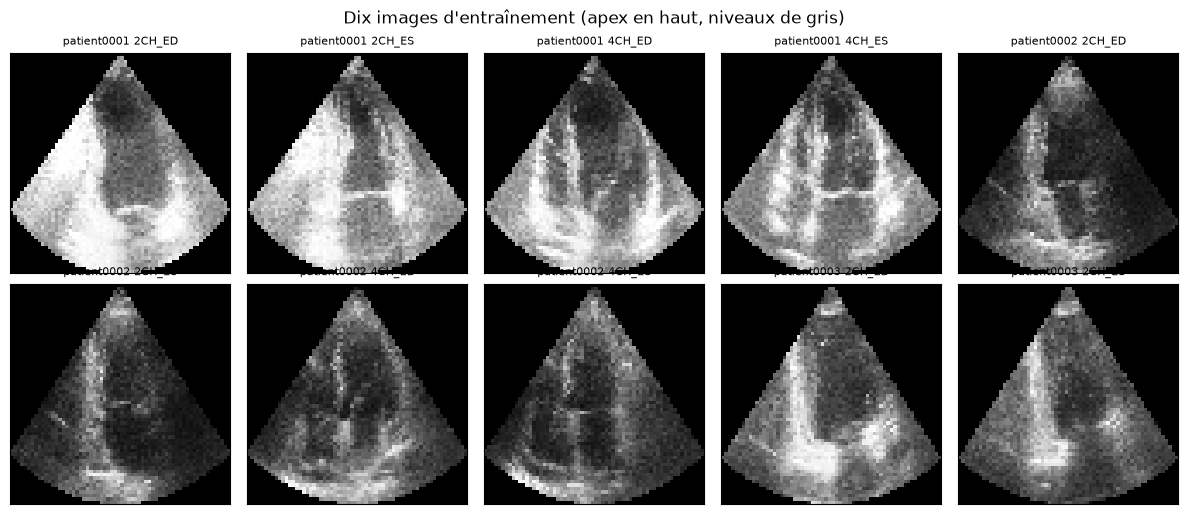

In [7]:
shapes = set()
mins, maxs = [], []
for subset in (train_dataset, valid_dataset, test_dataset):
    for record in subset.records:
        image = record["image"]
        shapes.add(tuple(image.shape))
        mins.append(float(image.min()))
        maxs.append(float(image.max()))
        stored = record["lv_area"]
        computed = float((record["label"].numpy() == 1).mean())
        assert abs(stored - computed) < 1e-6

assert shapes == {(IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)}, shapes
assert min(mins) >= 0.0 and max(maxs) <= 1.0
print(f"Forme unique : {shapes.pop()}   canal d'entrée in_channels={IN_CHANNELS}")
print(f"Intensités sur les trois sous-ensembles : [{min(mins):.3f}, {max(maxs):.3f}]")

probe_batch = next(iter(train_loader))
area_batch = torch.as_tensor(probe_batch["lv_area"], dtype=torch.float32)
area_from_label = (probe_batch["label"] == 1).float().mean(dim=(1, 2))
assert torch.allclose(area_batch, area_from_label, atol=1e-5)
print(f"Collation de lv_area : tenseur {tuple(area_batch.shape)}, aligné sur le masque.")


def mean_lv_area(records, instant=None, view=None):
    values = [
        record["lv_area"]
        for record in records
        if (instant is None or record["instant"] == instant)
        and (view is None or record["view"] == view)
    ]
    return float(np.mean(values))


for name, subset in (
    ("entraînement", train_dataset),
    ("validation", valid_dataset),
    ("test", test_dataset),
):
    counts = Counter(record["view_instant"] for record in subset.records)
    print(
        f"{name:14s} {dict(sorted(counts.items()))}  "
        f"lv_area ED {mean_lv_area(subset.records, 'ED'):.4f}  "
        f"ES {mean_lv_area(subset.records, 'ES'):.4f}"
    )

assert mean_lv_area(train_dataset.records, "ED") > mean_lv_area(train_dataset.records, "ES")
heart_fraction = float(np.mean([
    (record["label"] > 0).float().mean().item()
    for record in train_dataset.records
]))
print(f"Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : {heart_fraction:.3f}")
print(f"Aire moyenne de la cavité VG sur l'entraînement : {mean_lv_area(train_dataset.records):.3f}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, index in zip(axes.ravel(), range(10)):
    record = train_dataset[index]
    ax.imshow(record["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{record['patient']} {record['view_instant']}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Dix images d'entraînement (apex en haut, niveaux de gris)")
fig.tight_layout()
plt.show()


## 2. Architecture (`AutoencoderKL`)

L'encodeur produit les paramètres d'une gaussienne diagonale. Trois sous-échantillonnages mènent de 64×64 à 8×8. Huit canaux latents donnent un code 8×8×8, soit 512 coefficients. Deux blocs résiduels à chaque échelle donnent de la profondeur pour les parois fines et la texture échographique. Les groupes de normalisation sont 32, et aucune attention, locale ou non locale, n'est activée.

À l'entraînement, le décodeur reçoit z = μ + ε σ. À l'évaluation, il reçoit μ. `forward` rééchantillonne même en mode `eval`, donc l'entraînement et la validation appellent `encode`, `sampling` et `decode` explicitement.


In [8]:
CHANNELS = (32, 64, 128, 128)
LATENT_CHANNELS = 8
ATTENTION_LEVELS = (False, False, False, False)
NORM_GROUPS = 32
NUM_RES_BLOCKS = 2

assert all(channel % NORM_GROUPS == 0 for channel in CHANNELS)
assert len(ATTENTION_LEVELS) == len(CHANNELS)


def build_vae(seed=SEED):
    set_seed(seed)
    model = AutoencoderKL(
        spatial_dims=2,
        in_channels=IN_CHANNELS,
        out_channels=1,
        num_res_blocks=NUM_RES_BLOCKS,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return model.to(device)


model = build_vae(SEED)
print(summary(
    model.cpu(),
    input_size=(BATCH_SIZE, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
    depth=2,
    col_names=["input_size", "output_size", "num_params"],
    verbose=0,
    device="cpu",
))
model.to(device)

with torch.no_grad():
    probe, mu, sigma = model(torch.zeros(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device))

LATENT_SHAPE = tuple(mu.shape[1:])
downsamples = len(CHANNELS) - 1
expected_latent = (
    LATENT_CHANNELS,
    IMAGE_SIZE // 2 ** downsamples,
    IMAGE_SIZE // 2 ** downsamples,
)
assert LATENT_SHAPE == expected_latent, (LATENT_SHAPE, expected_latent)
assert tuple(sigma.shape[1:]) == LATENT_SHAPE
assert tuple(probe.shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

N_PARAMS = sum(parameter.numel() for parameter in model.parameters())
pixels = IN_CHANNELS * IMAGE_SIZE * IMAGE_SIZE
latent_size = int(np.prod(LATENT_SHAPE))
print(f"Reconstruction {tuple(probe.shape)}, moyenne latente {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Paramètres entraînables : {N_PARAMS:,}".replace(",", " "))
print(f"Code latent : {latent_size} coefficients pour {pixels} pixels, compression ×{pixels / latent_size:.0f}")
print(f"VRAM allouée après un passage : {torch.cuda.memory_allocated(0) / 1024 ** 2:.1f} Mo")
print("Convolutions du goulot :")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(model, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(
        f"  {name}: noyau {tuple(conv.kernel_size)}, "
        f"pas {tuple(conv.stride)}, padding {tuple(conv.padding)}"
    )


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderKL                            [64, 1, 64, 64]           [64, 1, 64, 64]           --
├─Encoder: 1-1                           [64, 1, 64, 64]           [64, 8, 8, 8]             --
│    └─ModuleList: 2-1                   --                        --                        1,489,832
├─Convolution: 1-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Decoder: 1-5              

Reconstruction (1, 1, 64, 64), moyenne latente (8, 8, 8), sigma (1, 8, 8, 8)
Paramètres entraînables : 3 256 641
Code latent : 512 coefficients pour 4096 pixels, compression ×8
VRAM allouée après un passage : 12.5 Mo
Convolutions du goulot :
  quant_conv_mu: noyau (1, 1), pas (1, 1), padding (0, 0)
  quant_conv_log_sigma: noyau (1, 1), pas (1, 1), padding (0, 0)
  post_quant_conv: noyau (1, 1), pas (1, 1), padding (0, 0)


## 3. Perte tri-hybride et entraînement

La carte de poids sert uniquement dans la perte d'entraînement et de validation :

$$W = 1 + 3 \cdot \mathbf{1}(\mathrm{label} > 0)$$

Un pixel du cœur vaut 4, un pixel du fond vaut 1.

$$L_{\mathrm{mse},w} = \frac{\sum W (\hat{x} - x)^2}{\sum W}, \qquad L_{1,w} = \frac{\sum W |\hat{x} - x|}{\sum W}$$

$$L_{\mathrm{ssim}} = \mathrm{SSIMLoss}\big(\mathrm{clamp}(\hat{x}, 0, 1), x\big)$$

$$L_{\mathrm{recon}} = 0{,}50 \, L_{\mathrm{mse},w} + 0{,}25 \, L_{1,w} + 0{,}25 \, L_{\mathrm{ssim}}$$

La MSE non pondérée est enregistrée à chaque époque pour la comparaison avec les expériences précédentes. Le gradient de reconstruction vient des trois termes ci-dessus. `SSIMLoss` (fenêtre 7, `data_range` 1) vaut 1 − SSIM et voit l'image bornée à [0, 1]. La MSE pondérée et la L1 voient la sortie brute.

β monte linéairement de 0 à l'époque 1 jusqu'à \(\beta_{\max} = 5 \times 10^{-5}\) à l'époque 10, puis reste constant. La KL régularise la gaussienne latente sans reprendre la priorité à la reconstruction.

L'attribut est la moyenne spatiale du premier canal, \(z_0 = \mu[:, 0]\) moyenné sur les 8×8 positions. Pour chaque paire d'images du lot, avec \(a\) l'aire de la cavité :

$$L_{\mathrm{attr}} = \mathrm{moyenne}_{i \neq j} \big| \tanh(2 (z_{0,i} - z_{0,j})) - \mathrm{signe}(a_i - a_j) \big|$$

γ = 0,05 place ce terme au même ordre de grandeur que la reconstruction. Le checkpoint retenu est la plus faible perte totale de validation à partir de l'époque 10, une fois β arrivé à son plateau.


β max = 5e-05   γ = 0.05   δ = 2.0   époques = 80   TRAIN = True
Calendrier de β :
  époque 01  β = 0.000e+00
  époque 02  β = 5.556e-06
  époque 05  β = 2.222e-05
  époque 10  β = 5.000e-05
  époque 11  β = 5.000e-05


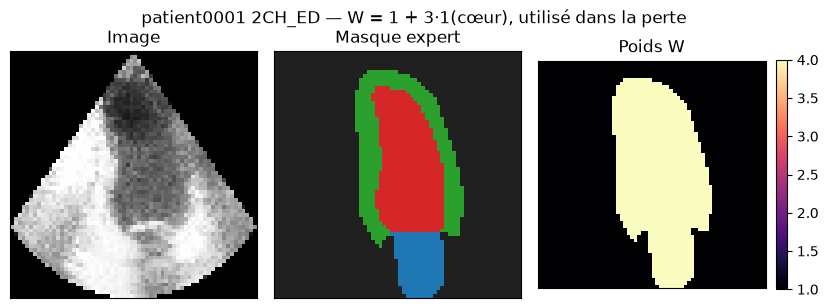

In [9]:
BETA_MAX = 5e-5
WARMUP_EPOCHS = 10
GAMMA = 0.05
DELTA = 2.0
MSE_WEIGHT = 0.50
L1_WEIGHT = 0.25
SSIM_WEIGHT = 0.25
HEART_WEIGHT = 3.0
LR = 1e-3
WEIGHT_DECAY = 1e-5
ETA_MIN = 1e-5
N_EPOCHS = int(os.environ.get("CAMUS_EXP4_EPOCHS", "80"))
TRAIN = os.environ.get("CAMUS_EXP4_TRAIN", "1") not in {"0", "false", "False"}

ssim_loss = SSIMLoss(spatial_dims=2, data_range=1.0, win_size=7).to(device)


def beta_at(epoch):
    # Époque 1 : 0. Époque 10 et suivantes : BETA_MAX.
    progress = (epoch - 1) / (WARMUP_EPOCHS - 1)
    return BETA_MAX * min(1.0, max(0.0, progress))


def kl_divergence(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(
        mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1,
        dim=tuple(range(1, mu.ndim)),
    )
    return kl.mean()


def attribute_loss(mu, area):
    z0 = mu[:, 0].mean(dim=(1, 2))
    if z0.shape[0] < 2:
        return z0.new_zeros(())
    diff_z = z0[:, None] - z0[None, :]
    diff_a = area[:, None] - area[None, :]
    eye = torch.eye(z0.shape[0], dtype=torch.bool, device=z0.device)
    residual = torch.tanh(DELTA * diff_z) - torch.sign(diff_a)
    return residual.abs()[~eye].mean()


def batch_losses(recon, image, label, mu, sigma, beta):
    weights = 1.0 + HEART_WEIGHT * (label > 0).to(dtype=recon.dtype).unsqueeze(1)
    error = recon - image
    denom = weights.sum().clamp_min(1.0)
    mse_w = (weights * error.pow(2)).sum() / denom
    l1_w = (weights * error.abs()).sum() / denom
    ssim_term = ssim_loss(recon.clamp(0, 1), image)
    recon_loss = MSE_WEIGHT * mse_w + L1_WEIGHT * l1_w + SSIM_WEIGHT * ssim_term
    kl_loss = kl_divergence(mu, sigma)
    area = (label == 1).to(dtype=mu.dtype).mean(dim=(1, 2))
    attr = attribute_loss(mu, area)
    total = recon_loss + beta * kl_loss + GAMMA * attr
    mse = error.pow(2).mean().detach()
    return total, recon_loss.detach(), mse, kl_loss.detach(), attr.detach(), ssim_term.detach()


print(
    f"β max = {BETA_MAX:.0e}   γ = {GAMMA:.2f}   δ = {DELTA:.1f}   "
    f"époques = {N_EPOCHS}   TRAIN = {TRAIN}"
)
print("Calendrier de β :")
for epoch in (1, 2, 5, 10, 11):
    print(f"  époque {epoch:02d}  β = {beta_at(epoch):.3e}")

example = train_dataset[0]
label_np = example["label"].numpy()
weight_np = 1.0 + HEART_WEIGHT * (label_np > 0).astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
axes[0].imshow(example["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(label_np, cmap=HEART_CMAP, vmin=0, vmax=3, interpolation="nearest")
weight_image = axes[2].imshow(weight_np, cmap="magma", vmin=1, vmax=4)
axes[0].set_title("Image")
axes[1].set_title("Masque expert")
axes[2].set_title("Poids W")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(weight_image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle(
    f"{example['patient']} {example['view_instant']} — W = 1 + 3·1(cœur), utilisé dans la perte"
)
fig.tight_layout()
plt.show()


In [10]:
CONFIG = {
    "spatial_dims": 2,
    "in_channels": IN_CHANNELS,
    "out_channels": 1,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "latent_channels": LATENT_CHANNELS,
    "latent_shape": list(LATENT_SHAPE),
    "norm_num_groups": NORM_GROUPS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_mse_weight": MSE_WEIGHT,
    "recon_l1_weight": L1_WEIGHT,
    "recon_ssim_weight": SSIM_WEIGHT,
    "heart_weight": HEART_WEIGHT,
    "recon_loss": "0.50*weighted_mse+0.25*weighted_l1+0.25*ssim",
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "epochs": N_EPOCHS,
    "device": gpu_name,
}


def to_device(batch):
    images = batch["image"].to(device, non_blocking=True)
    labels = batch["label"].to(device, non_blocking=True)
    return images, labels


def train_vae(model, n_epochs, config, lr=LR):
    set_seed(SEED)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(n_epochs, 1), eta_min=ETA_MIN,
    )
    history = {
        key: []
        for key in (
            "train_total", "train_recon", "train_mse", "train_ssim", "train_kl", "train_attr",
            "val_total", "val_recon", "val_mse", "val_ssim", "val_kl", "val_attr",
            "beta", "lr",
        )
    }
    history.update({
        "beta_max": BETA_MAX,
        "gamma": GAMMA,
        "delta": DELTA,
        "epochs": n_epochs,
        "warmup_epochs": WARMUP_EPOCHS,
        "recon": CONFIG["recon_loss"],
    })
    best_score = float("inf")
    best_state = None
    best_epoch = 0
    first_selectable = min(WARMUP_EPOCHS, n_epochs)
    torch.cuda.reset_peak_memory_stats()
    clock = time.perf_counter()
    log_path = ARTIFACT_DIR / "exp4_train.log"
    log_file = log_path.open("w", encoding="utf-8")
    print(f"Checkpoint à partir de l'époque {first_selectable}. Journal : {log_path}")

    for epoch in range(n_epochs):
        beta = beta_at(epoch + 1)
        lr_now = float(optimizer.param_groups[0]["lr"])
        model.train()
        totals = {key: 0.0 for key in ("total", "recon", "mse", "ssim", "kl", "attr")}
        seen = 0
        for batch in train_loader:
            images, labels = to_device(batch)
            optimizer.zero_grad(set_to_none=True)
            mu, sigma = model.encode(images)
            z = model.sampling(mu, sigma)
            recon = model.decode(z)
            total, recon_loss, mse, kl_loss, attr, ssim_term = batch_losses(
                recon, images, labels, mu, sigma, beta,
            )
            if not torch.isfinite(total):
                raise RuntimeError(f"Perte d'entraînement non finie à l'époque {epoch + 1}")
            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_size = images.size(0)
            totals["total"] += float(total.detach()) * batch_size
            totals["recon"] += float(recon_loss) * batch_size
            totals["mse"] += float(mse) * batch_size
            totals["ssim"] += (1.0 - float(ssim_term)) * batch_size
            totals["kl"] += float(kl_loss) * batch_size
            totals["attr"] += float(attr) * batch_size
            seen += batch_size
        train_means = {key: value / seen for key, value in totals.items()}

        model.eval()
        totals = {key: 0.0 for key in ("total", "recon", "mse", "ssim", "kl", "attr")}
        seen = 0
        with torch.no_grad():
            for batch in valid_loader:
                images, labels = to_device(batch)
                mu, sigma = model.encode(images)
                recon = model.decode(mu)
                total, recon_loss, mse, kl_loss, attr, ssim_term = batch_losses(
                    recon, images, labels, mu, sigma, beta,
                )
                if not torch.isfinite(total):
                    raise RuntimeError(f"Perte de validation non finie à l'époque {epoch + 1}")
                batch_size = images.size(0)
                totals["total"] += float(total) * batch_size
                totals["recon"] += float(recon_loss) * batch_size
                totals["mse"] += float(mse) * batch_size
                totals["ssim"] += (1.0 - float(ssim_term)) * batch_size
                totals["kl"] += float(kl_loss) * batch_size
                totals["attr"] += float(attr) * batch_size
                seen += batch_size
        val_means = {key: value / seen for key, value in totals.items()}

        history["train_total"].append(train_means["total"])
        history["train_recon"].append(train_means["recon"])
        history["train_mse"].append(train_means["mse"])
        history["train_ssim"].append(train_means["ssim"])
        history["train_kl"].append(train_means["kl"])
        history["train_attr"].append(train_means["attr"])
        history["val_total"].append(val_means["total"])
        history["val_recon"].append(val_means["recon"])
        history["val_mse"].append(val_means["mse"])
        history["val_ssim"].append(val_means["ssim"])
        history["val_kl"].append(val_means["kl"])
        history["val_attr"].append(val_means["attr"])
        history["beta"].append(beta)
        history["lr"].append(lr_now)

        saved = False
        if (epoch + 1) >= first_selectable and val_means["total"] < best_score:
            best_score = val_means["total"]
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            history["best_epoch"] = best_epoch
            history["best_val"] = best_score
            torch.save(
                {
                    "state_dict": best_state,
                    "epoch": best_epoch,
                    "history": history,
                    "config": config,
                },
                CHECKPOINT_PATH,
            )
            saved = True

        flag = "  checkpoint" if saved else ""
        line = (
            f"Époque {epoch + 1:02d}/{n_epochs}  "
            f"β={beta:.2e}  lr={lr_now:.2e}  "
            f"train {train_means['total']:.5f} "
            f"(recon {train_means['recon']:.5f}, mse {train_means['mse']:.5f}, "
            f"ssim {train_means['ssim']:.3f}, kl {train_means['kl']:.2f}, "
            f"attr {train_means['attr']:.4f})  "
            f"val {val_means['total']:.5f} "
            f"(recon {val_means['recon']:.5f}, mse {val_means['mse']:.5f}, "
            f"ssim {val_means['ssim']:.3f}, kl {val_means['kl']:.2f}, "
            f"attr {val_means['attr']:.4f})"
            f"{flag}"
        )
        print(line, flush=True)
        log_file.write(line + "\n")
        log_file.flush()
        scheduler.step()

    history["seconds"] = time.perf_counter() - clock
    history["best_epoch"] = best_epoch
    history["best_val"] = best_score
    history["max_memory_mb"] = torch.cuda.max_memory_allocated() / (1024 ** 2)
    if best_state is None:
        raise RuntimeError("Aucun checkpoint : la sélection n'a retenu aucune époque.")
    model.load_state_dict(best_state)
    torch.save(
        {
            "state_dict": best_state,
            "epoch": best_epoch,
            "history": history,
            "config": config,
        },
        CHECKPOINT_PATH,
    )
    log_file.write(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"perte de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo.\n"
    )
    log_file.close()
    print(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"perte de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo."
    )
    print(f"Poids enregistrés dans {CHECKPOINT_PATH}.")
    return model, history


model = build_vae(SEED)
if TRAIN:
    model, history = train_vae(model, N_EPOCHS, CONFIG, lr=LR)
else:
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
    payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(payload["state_dict"])
    history = payload["history"]
    print(f"Poids rechargés : {CHECKPOINT_PATH} (époque {history['best_epoch']})")


Checkpoint à partir de l'époque 10. Journal : artifacts\exp4_train.log


Époque 01/80  β=0.00e+00  lr=1.00e-03  train 0.32528 (recon 0.27677, mse 0.09576, ssim 0.319, kl 782.83, attr 0.9701)  val 0.23222 (recon 0.18802, mse 0.03560, ssim 0.447, kl 1251.05, attr 0.8840)


Époque 02/80  β=5.56e-06  lr=1.00e-03  train 0.22099 (recon 0.17847, mse 0.02997, ssim 0.473, kl 821.15, attr 0.7591)  val 0.18938 (recon 0.15733, mse 0.01944, ssim 0.516, kl 675.06, attr 0.5659)


Époque 03/80  β=1.11e-05  lr=9.98e-04  train 0.17683 (recon 0.14709, mse 0.01808, ssim 0.552, kl 616.48, attr 0.4578)  val 0.15529 (recon 0.12907, mse 0.01570, ssim 0.617, kl 530.20, attr 0.4067)


Époque 04/80  β=1.67e-05  lr=9.97e-04  train 0.16139 (recon 0.13535, mse 0.01520, ssim 0.586, kl 499.47, attr 0.3543)  val 0.17604 (recon 0.15022, mse 0.02569, ssim 0.580, kl 520.31, attr 0.3430)


Époque 05/80  β=2.22e-05  lr=9.94e-04  train 0.17088 (recon 0.14432, mse 0.01885, ssim 0.572, kl 446.61, attr 0.3327)  val 0.18109 (recon 0.15285, mse 0.02403, ssim 0.565, kl 408.18, attr 0.3834)


... (72 outputs left out)

Époque 78/80  β=5.00e-05  lr=1.34e-05  train 0.08386 (recon 0.06474, mse 0.00330, ssim 0.791, kl 252.75, attr 0.1296)  val 0.08989 (recon 0.06265, mse 0.00290, ssim 0.796, kl 236.56, attr 0.3082)


Époque 79/80  β=5.00e-05  lr=1.15e-05  train 0.08382 (recon 0.06468, mse 0.00329, ssim 0.792, kl 252.44, attr 0.1304)  val 0.08986 (recon 0.06261, mse 0.00290, ssim 0.797, kl 236.43, attr 0.3085)


Époque 80/80  β=5.00e-05  lr=1.04e-05  train 0.08389 (recon 0.06464, mse 0.00329, ssim 0.792, kl 252.65, attr 0.1323)  val 0.08995 (recon 0.06268, mse 0.00290, ssim 0.796, kl 236.78, attr 0.3086)


Meilleure époque 76/80, perte de validation 0.089849, durée 3.75 min, VRAM crête 2453 Mo.
Poids enregistrés dans checkpoints\exp4_vae_best.pth.


### Courbes

La courbe de SSIM vaut 1 − SSIMLoss, avec la même fenêtre que le terme optimisé. La MSE tracée est la MSE brute, celle des tableaux de test.


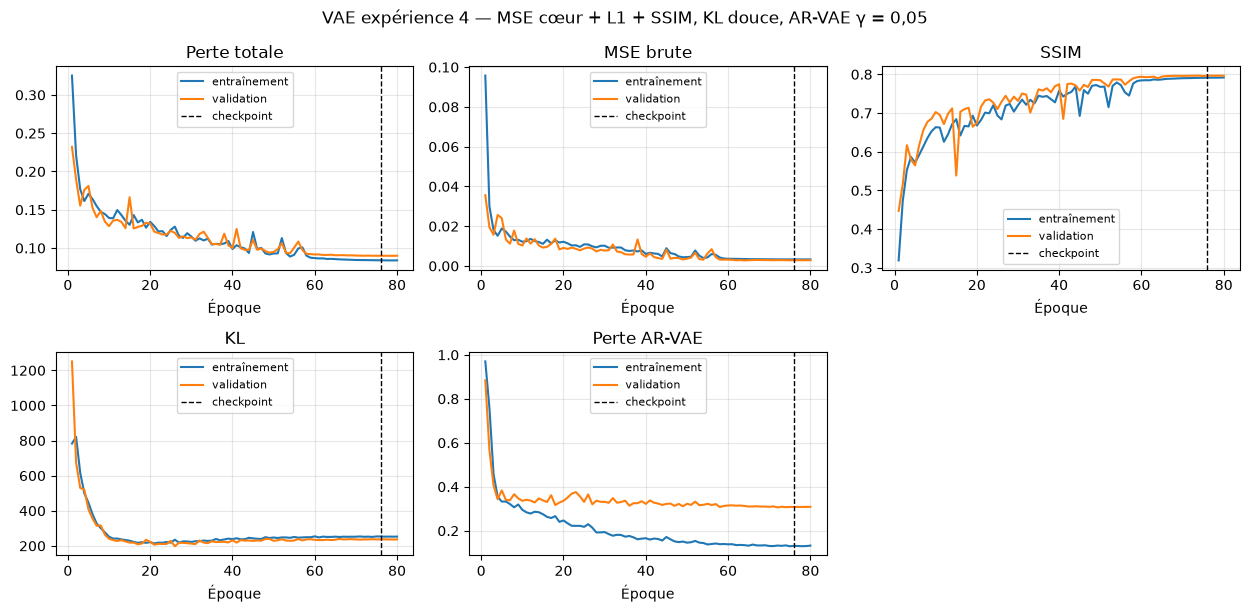

In [11]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.2))
    series = (
        ("total", "Perte totale"),
        ("mse", "MSE brute"),
        ("ssim", "SSIM"),
        ("kl", "KL"),
        ("attr", "Perte AR-VAE"),
    )
    for ax, (key, title) in zip(axes.ravel(), series):
        ax.plot(epochs, history[f"train_{key}"], label="entraînement")
        ax.plot(epochs, history[f"val_{key}"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
        ax.set_title(title)
        ax.set_xlabel("Époque")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    axes.ravel()[5].axis("off")
    fig.suptitle("VAE expérience 4 — MSE cœur + L1 + SSIM, KL douce, AR-VAE γ = 0,05")
    fig.tight_layout()
    plt.show()


plot_history(history)


## 4. Évaluation

Les métriques de test décodent μ. La MSE, la MAE, le PSNR et le SSIM utilisent les mêmes définitions que les expériences 1 à 3 : PSNR avec `max_val` 1, SSIM de MONAI avec une fenêtre de 7. La MSE cœur moyenne l'erreur quadratique sur les pixels `label > 0`. La MSE fond fait de même sur `label == 0`.


Poids rechargés : époque 76, perte de validation 0.089849, durée 3.75 min.
MSE moyenne sur les 200 images de test : 0.00343 ± 0.00261
MAE test :  0.034 ± 0.010
PSNR test : 25.12 ± 1.70 dB
SSIM test : 0.787 ± 0.030
MSE sur le cœur : 0.00518 ± 0.00206
MSE sur le fond : 0.00292 ± 0.00315


### MSE, PSNR et SSIM de test par vue et par instant

| Vue / instant | n | MSE | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| 2CH_ED | 50 | 0.00342 | 25.18 | 0.783 |
| 2CH_ES | 50 | 0.00324 | 25.47 | 0.780 |
| 4CH_ED | 50 | 0.00367 | 24.72 | 0.793 |
| 4CH_ES | 50 | 0.00340 | 25.10 | 0.794 |

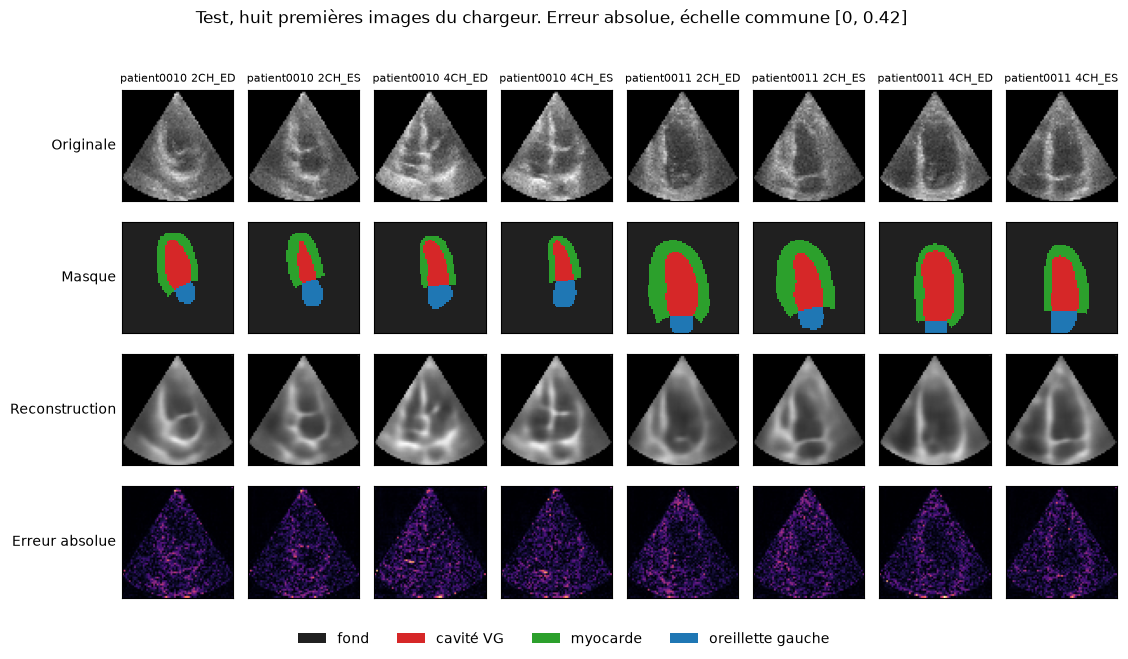

In [12]:
def make_ssim():
    return SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def reconstruction_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim


def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.mean(values)), float(np.std(values))


def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"


def fmt_pm(mean, std, digits):
    if mean is None:
        return "n.d."
    if std is None:
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def fmt_int(value):
    if value is None:
        return "n.d."
    return f"{int(value):,}".replace(",", " ")


def masked_mse(recon, image, label, inside):
    error = (recon - image).pow(2)
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()


def as_float_vector(value):
    if torch.is_tensor(value):
        return value.detach().cpu().float().reshape(-1)
    return torch.tensor(value, dtype=torch.float32).reshape(-1)


@torch.no_grad()
def collect_predictions(net, loader):
    net.eval()
    images, recons, labels, mus, areas = [], [], [], [], []
    view_instants, views, instants, patients = [], [], [], []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        mu, sigma = net.encode(x)
        recon = net.decode(mu)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        mus.append(mu.cpu())
        areas.append(as_float_vector(batch["lv_area"]))
        view_instants.extend(list(batch["view_instant"]))
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "mu": torch.cat(mus),
        "lv_area": torch.cat(areas).numpy(),
        "view_instant": np.asarray(view_instants),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
    }
    mae, mse, psnr, ssim = reconstruction_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)


if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
saved_config = payload["config"]
assert tuple(saved_config["channels"]) == tuple(CHANNELS)
assert saved_config["latent_channels"] == LATENT_CHANNELS
assert saved_config["num_res_blocks"] == NUM_RES_BLOCKS
model.load_state_dict(payload["state_dict"])
history = payload["history"]
model.eval()
print(
    f"Poids rechargés : époque {payload['epoch']}, "
    f"perte de validation {history['best_val']:.6f}, "
    f"durée {history['seconds'] / 60:.2f} min."
)

test_pred = collect_predictions(model, test_loader)
assert len(test_pred["mse"]) == len(test_dataset) == 200
heart_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=True)
background_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=False)

print(f"MSE moyenne sur les {len(test_dataset)} images de test : {fmt_mean_std(test_pred['mse'], digits=5)}")
print(f"MAE test :  {fmt_mean_std(test_pred['mae'])}")
print(f"PSNR test : {fmt_mean_std(test_pred['psnr'], digits=2)} dB")
print(f"SSIM test : {fmt_mean_std(test_pred['ssim'])}")
print(f"MSE sur le cœur : {fmt_mean_std(heart_mse, digits=5)}")
print(f"MSE sur le fond : {fmt_mean_std(background_mse, digits=5)}")

per_class_rows = []
per_view_instant = {}
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    mse_mean, mse_std = mean_std(test_pred["mse"][selected])
    psnr_mean, psnr_std = mean_std(test_pred["psnr"][selected])
    ssim_mean, ssim_std = mean_std(test_pred["ssim"][selected])
    per_class_rows.append([
        view_instant,
        int(selected.sum()),
        f"{mse_mean:.5f}",
        f"{psnr_mean:.2f}",
        f"{ssim_mean:.3f}",
    ])
    per_view_instant[view_instant] = {
        "n": int(selected.sum()),
        "mse_mean": mse_mean,
        "mse_std": mse_std,
        "psnr_mean": psnr_mean,
        "psnr_std": psnr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
    }

display(Markdown(
    "### MSE, PSNR et SSIM de test par vue et par instant\n\n"
    + markdown_table(["Vue / instant", "n", "MSE", "PSNR (dB)", "SSIM"], per_class_rows)
))

n_show = 8
shown_error = (test_pred["recon"][:n_show] - test_pred["image"][:n_show]).abs()
error_vmax = float(shown_error.max().clamp_min(1e-3))
fig, axes = plt.subplots(4, n_show, figsize=(1.45 * n_show, 6.6))
row_names = ("Originale", "Masque", "Reconstruction", "Erreur absolue")
for index in range(n_show):
    axes[0, index].imshow(test_pred["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].imshow(
        test_pred["label"][index].numpy(),
        cmap=HEART_CMAP,
        vmin=0,
        vmax=3,
        interpolation="nearest",
    )
    axes[2, index].imshow(test_pred["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[3, index].imshow(shown_error[index, 0].numpy(), cmap="magma", vmin=0, vmax=error_vmax)
    axes[0, index].set_title(
        f"{test_pred['patient'][index]} {test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for row in range(4):
        axes[row, index].set_xticks([])
        axes[row, index].set_yticks([])
for row, name in enumerate(row_names):
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
legend = [
    Patch(facecolor=HEART_CMAP(index / 3), edgecolor="none", label=LABEL_NAMES[index])
    for index in range(4)
]
fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False)
fig.suptitle(
    f"Test, huit premières images du chargeur. Erreur absolue, échelle commune [0, {error_vmax:.2f}]"
)
fig.tight_layout(rect=(0.02, 0.05, 1, 0.96))
plt.show()


### Comparaison des quatre expériences

Les fichiers `artifacts/results_exp2.json` et `artifacts/results_exp3.json` sont relus lorsqu'ils sont présents. Sinon, le tableau reprend les chiffres imprimés par les notebooks déjà exécutés. Pour l'expérience 1, ces sorties donnent 25 époques au VAE final (26,8 min, 473 649 paramètres), et non 20. Une valeur en gras est la meilleure de la ligne : plus basse pour les erreurs et les durées, plus haute pour le PSNR, le SSIM et le Spearman.


In [13]:
PUBLISHED = {
    "1": {
        "name": "Expérience 1",
        "hardware": "CPU",
        "latent": "4×8×8",
        "n_params": 473_649,
        "epochs": 25,
        "best_epoch": 25,
        "seconds": 26.8 * 60,
        "mse": 0.01024,
        "mse_std": 0.01093,
        "mae": 0.057,
        "mae_std": 0.026,
        "psnr": 20.97,
        "psnr_std": 2.68,
        "ssim": 0.622,
        "ssim_std": 0.070,
        "heart_mse": 0.01511,
        "heart_mse_std": 0.01215,
        "background_mse": 0.00871,
        "background_mse_std": 0.01079,
        "spearman": None,
        "source": "tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques)",
    },
    "2": {
        "name": "Expérience 2",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 1_888_449,
        "epochs": 20,
        "best_epoch": 19,
        "seconds": 30.5 * 60,
        "mse": 0.00765,
        "mse_std": 0.00538,
        "mae": 0.055,
        "mae_std": 0.016,
        "psnr": 21.70,
        "psnr_std": 1.92,
        "ssim": 0.445,
        "ssim_std": 0.065,
        "heart_mse": 0.01073,
        "heart_mse_std": 0.00486,
        "background_mse": 0.00678,
        "background_mse_std": 0.00624,
        "spearman": None,
        "source": "sorties exécutées de exp_2_vae_camus.ipynb",
    },
    "3": {
        "name": "Expérience 3",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 478_417,
        "epochs": 20,
        "best_epoch": 20,
        "seconds": 12.6 * 60,
        "mse": 0.01024,
        "mse_std": 0.01042,
        "mae": 0.061,
        "mae_std": 0.026,
        "psnr": 20.84,
        "psnr_std": 2.48,
        "ssim": 0.703,
        "ssim_std": 0.052,
        "heart_mse": 0.01298,
        "heart_mse_std": 0.01028,
        "background_mse": 0.00938,
        "background_mse_std": 0.01090,
        "spearman": 0.023,
        "source": "sorties exécutées de exp_3_vae_camus.ipynb",
    },
}


def load_json(path):
    if not path.is_file():
        print(f"{path} est absent. Chiffres publiés dans le notebook correspondant.")
        return None
    print(f"Lecture de {path}.")
    return json.loads(path.read_text(encoding="utf-8"))


def column_from_report(name, report, hardware, source):
    test = report["test"]
    latent = report.get("latent_shape")
    spearman = None
    latent_block = report.get("latent_attribute") or {}
    if "spearman_mu0_lv_area" in latent_block:
        spearman = float(latent_block["spearman_mu0_lv_area"])
    column = {
        "name": name,
        "hardware": hardware,
        "latent": "×".join(str(value) for value in latent) if latent else None,
        "n_params": report.get("n_params"),
        "epochs": report.get("epochs"),
        "best_epoch": report.get("best_epoch"),
        "seconds": report.get("seconds"),
        "mse": test.get("mse_mean"),
        "mse_std": test.get("mse_std"),
        "mae": test.get("mae_mean"),
        "mae_std": test.get("mae_std"),
        "psnr": test.get("psnr_mean"),
        "psnr_std": test.get("psnr_std"),
        "ssim": test.get("ssim_mean"),
        "ssim_std": test.get("ssim_std"),
        "heart_mse": test.get("heart_mse_mean"),
        "heart_mse_std": test.get("heart_mse_std"),
        "background_mse": test.get("background_mse_mean"),
        "background_mse_std": test.get("background_mse_std"),
        "spearman": spearman,
        "source": source,
    }
    return column


exp2_report = load_json(ARTIFACT_DIR / "results_exp2.json")
exp3_report = load_json(ARTIFACT_DIR / "results_exp3.json")
column_exp1 = dict(PUBLISHED["1"])
column_exp2 = (
    column_from_report("Expérience 2", exp2_report, "CPU", "artifacts/results_exp2.json")
    if exp2_report is not None else dict(PUBLISHED["2"])
)
column_exp3 = (
    column_from_report("Expérience 3", exp3_report, "CPU", "artifacts/results_exp3.json")
    if exp3_report is not None else dict(PUBLISHED["3"])
)
if column_exp3.get("spearman") is None:
    column_exp3["spearman"] = PUBLISHED["3"]["spearman"]

exp4_mse, exp4_mse_std = mean_std(test_pred["mse"])
exp4_mae, exp4_mae_std = mean_std(test_pred["mae"])
exp4_psnr, exp4_psnr_std = mean_std(test_pred["psnr"])
exp4_ssim, exp4_ssim_std = mean_std(test_pred["ssim"])
exp4_heart, exp4_heart_std = mean_std(heart_mse)
exp4_background, exp4_background_std = mean_std(background_mse)

column_exp4 = {
    "name": "Expérience 4",
    "hardware": gpu_name,
    "latent": "×".join(str(value) for value in LATENT_SHAPE),
    "n_params": N_PARAMS,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "seconds": history["seconds"],
    "mse": exp4_mse,
    "mse_std": exp4_mse_std,
    "mae": exp4_mae,
    "mae_std": exp4_mae_std,
    "psnr": exp4_psnr,
    "psnr_std": exp4_psnr_std,
    "ssim": exp4_ssim,
    "ssim_std": exp4_ssim_std,
    "heart_mse": exp4_heart,
    "heart_mse_std": exp4_heart_std,
    "background_mse": exp4_background,
    "background_mse_std": exp4_background_std,
    "spearman": None,
    "source": "test_loader, checkpoints/exp4_vae_best.pth",
}
comparison_columns = {"1": column_exp1, "2": column_exp2, "3": column_exp3, "4": column_exp4}


def minutes_display(column):
    if column["seconds"] is None:
        return "n.d."
    minutes = column["seconds"] / 60
    return f"{minutes:.1f} min" if minutes >= 1 else f"{minutes * 60:.1f} s"


def per_epoch_display(column):
    if column["seconds"] is None or not column["epochs"]:
        return "n.d."
    value = column["seconds"] / column["epochs"]
    column["seconds_per_epoch"] = value
    return f"{value:.1f} s" if value >= 10 else f"{value:.2f} s"


def epochs_display(column):
    if column["epochs"] is None:
        return "n.d."
    if column["best_epoch"] is None:
        return str(column["epochs"])
    return f"{column['epochs']} (meilleure {column['best_epoch']})"


def mark_best(displays, values, higher):
    valid = [value for value in values if value is not None]
    if not valid:
        return displays
    target = max(valid) if higher else min(valid)
    marked = []
    for display, value in zip(displays, values):
        if value is not None and abs(value - target) <= 1e-9 * max(1.0, abs(target)):
            marked.append(f"**{display}**")
        else:
            marked.append(display)
    return marked


ordered = [column_exp1, column_exp2, column_exp3, column_exp4]
headers = ["", *[column["name"] for column in ordered]]


def row(label, displays, values, higher):
    return [label, *mark_best(displays, values, higher)]


table_rows = [
    ["Matériel", *[column["hardware"] for column in ordered]],
    ["Code latent", *[column["latent"] or "n.d." for column in ordered]],
    ["Paramètres", *[fmt_int(column["n_params"]) for column in ordered]],
    ["Époques", *[epochs_display(column) for column in ordered]],
    row(
        "Durée totale",
        [minutes_display(column) for column in ordered],
        [column["seconds"] for column in ordered],
        higher=False,
    ),
    row(
        "Durée par époque",
        [per_epoch_display(column) for column in ordered],
        [column.get("seconds_per_epoch") for column in ordered],
        higher=False,
    ),
    row(
        "MSE test",
        [fmt_pm(column["mse"], column["mse_std"], 5) for column in ordered],
        [column["mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MAE test",
        [fmt_pm(column["mae"], column["mae_std"], 3) for column in ordered],
        [column["mae"] for column in ordered],
        higher=False,
    ),
    row(
        "PSNR test (dB)",
        [fmt_pm(column["psnr"], column["psnr_std"], 2) for column in ordered],
        [column["psnr"] for column in ordered],
        higher=True,
    ),
    row(
        "SSIM test",
        [fmt_pm(column["ssim"], column["ssim_std"], 3) for column in ordered],
        [column["ssim"] for column in ordered],
        higher=True,
    ),
    row(
        "MSE cœur",
        [fmt_pm(column["heart_mse"], column["heart_mse_std"], 5) for column in ordered],
        [column["heart_mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MSE fond",
        [fmt_pm(column["background_mse"], column["background_mse_std"], 5) for column in ordered],
        [column["background_mse"] for column in ordered],
        higher=False,
    ),
]

display(Markdown(
    "### Test, expériences 1, 2, 3 et 4\n\n"
    + markdown_table(headers, table_rows)
    + "\n\nSources : "
    + " ; ".join(f"{column['name']} — {column['source']}" for column in ordered)
    + ". Le Spearman est ajouté après la lecture de l'espace latent."
))


artifacts\results_exp2.json est absent. Chiffres publiés dans le notebook correspondant.
artifacts\results_exp3.json est absent. Chiffres publiés dans le notebook correspondant.


### Test, expériences 1, 2, 3 et 4

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 |
| --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | **0.00343 ± 0.00261** |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | **0.034 ± 0.010** |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | **25.12 ± 1.70** |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | **0.787 ± 0.030** |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | **0.00518 ± 0.00206** |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | **0.00292 ± 0.00315** |

Sources : Expérience 1 — tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques) ; Expérience 2 — sorties exécutées de exp_2_vae_camus.ipynb ; Expérience 3 — sorties exécutées de exp_3_vae_camus.ipynb ; Expérience 4 — test_loader, checkpoints/exp4_vae_best.pth. Le Spearman est ajouté après la lecture de l'espace latent.

### Espace latent

Le premier panneau est coloré par le couple vue / instant. Ces étiquettes ne sont pas dans la perte. Le deuxième est coloré par `lv_area`. Le troisième rapporte \(z_0\), la moyenne spatiale de μ[:, 0], à cette aire. La perte d'attribut pousse \(z_0\) à croître avec l'aire : le Spearman est la mesure qui correspond au terme en signe.


Matrice passée à t-SNE : (200, 512) = (images de test, coefficients latents).


Projection t-SNE : (200, 2)
Spearman(z0, lv_area) = 0.943  (p = 2.08e-96)
Pearson(z0, lv_area)  = 0.909  (p = 4.41e-77)
Spearman dans la vue 2CH (n = 100) : 0.943  (p = 1.17e-48)
Spearman dans la vue 4CH (n = 100) : 0.937  (p = 1.38e-46)


### Spearman de l'axe régularisé

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 |
| --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | **0.00343 ± 0.00261** |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | **0.034 ± 0.010** |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | **25.12 ± 1.70** |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | **0.787 ± 0.030** |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | **0.00518 ± 0.00206** |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | **0.00292 ± 0.00315** |
| Spearman(z0, aire VG) | n.d. | n.d. | 0.023 | **0.943** |

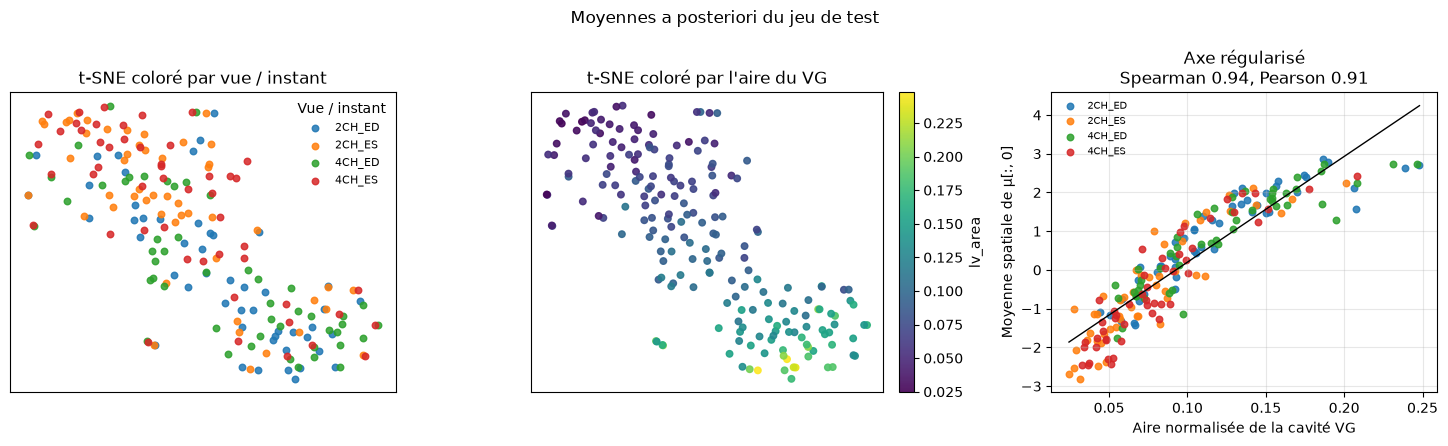

In [14]:
mu_np = test_pred["mu"].numpy()
flat = mu_np.reshape(mu_np.shape[0], -1)
print(f"Matrice passée à t-SNE : {flat.shape} = (images de test, coefficients latents).")
embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED,
).fit_transform(flat)
print(f"Projection t-SNE : {embedding.shape}")

z0 = test_pred["mu"][:, 0].mean(dim=(1, 2)).numpy()
lv_area = np.asarray(test_pred["lv_area"], dtype=np.float64)
spearman_rho, spearman_p = spearmanr(z0, lv_area)
pearson_r, pearson_p = pearsonr(z0, lv_area)
print(f"Spearman(z0, lv_area) = {spearman_rho:.3f}  (p = {spearman_p:.3g})")
print(f"Pearson(z0, lv_area)  = {pearson_r:.3f}  (p = {pearson_p:.3g})")

within_view = {}
for view in ("2CH", "4CH"):
    selected = test_pred["view"] == view
    rho, p_value = spearmanr(z0[selected], lv_area[selected])
    within_view[view] = {
        "spearman": float(rho),
        "pvalue": float(p_value),
        "n": int(selected.sum()),
    }
    print(f"Spearman dans la vue {view} (n = {int(selected.sum())}) : {rho:.3f}  (p = {p_value:.3g})")

column_exp4["spearman"] = float(spearman_rho)
spearman_displays = []
spearman_values = []
for column in ordered:
    if column["spearman"] is None:
        spearman_displays.append("n.d.")
        spearman_values.append(None)
    else:
        spearman_displays.append(f"{column['spearman']:.3f}")
        spearman_values.append(column["spearman"])
spearman_row = ["Spearman(z0, aire VG)", *mark_best(spearman_displays, spearman_values, higher=True)]
display(Markdown(
    "### Spearman de l'axe régularisé\n\n"
    + markdown_table(headers, table_rows + [spearman_row])
))

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.5))
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[0].scatter(
        embedding[selected, 0],
        embedding[selected, 1],
        s=22,
        alpha=0.85,
        label=view_instant,
    )
axes[0].legend(frameon=False, title="Vue / instant", fontsize=8)
axes[0].set_title("t-SNE coloré par vue / instant")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].grid(True, color="0.9")

area_scatter = axes[1].scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=lv_area,
    cmap="viridis",
    s=22,
    alpha=0.9,
)
axes[1].set_title("t-SNE coloré par l'aire du VG")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].grid(True, color="0.9")
fig.colorbar(area_scatter, ax=axes[1], fraction=0.046, pad=0.04, label="lv_area")

for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[2].scatter(lv_area[selected], z0[selected], s=22, alpha=0.85, label=view_instant)
order = np.argsort(lv_area)
slope, intercept = np.polyfit(lv_area, z0, 1)
axes[2].plot(lv_area[order], slope * lv_area[order] + intercept, color="black", lw=1.0)
axes[2].set_xlabel("Aire normalisée de la cavité VG")
axes[2].set_ylabel("Moyenne spatiale de μ[:, 0]")
axes[2].set_title(f"Axe régularisé\nSpearman {spearman_rho:.2f}, Pearson {pearson_r:.2f}")
axes[2].grid(True, alpha=0.3)
axes[2].legend(frameon=False, fontsize=7)
fig.suptitle("Moyennes a posteriori du jeu de test")
fig.tight_layout()
plt.show()


### Interpolation ED → ES

Le trajet relie la moyenne a posteriori de la télédiastole à celle de la télésystole pour `patient0010` en vue 4CH, les deux cadres étant dans le test. Le GIF fait l'aller puis le retour.


patient0010 4CH : interpolation de μ_ED vers μ_ES, 16 pas.
GIF aller-retour enregistré dans artifacts\exp4_interp_ED_ES.gif.


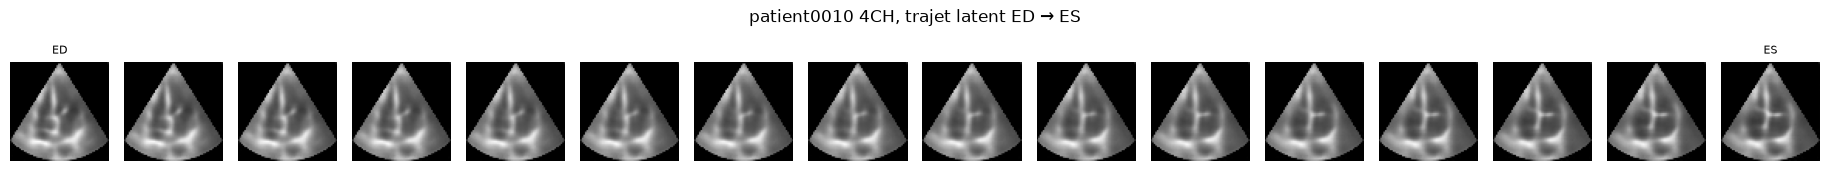

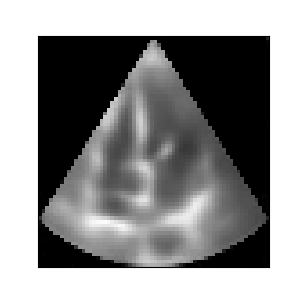

In [15]:
def pair_index(dataset):
    pairs = {}
    for index, record in enumerate(dataset.records):
        pairs.setdefault((record["patient"], record["view"]), {})[record["instant"]] = index
    return pairs


def encode_mu(model, dataset, index):
    image = dataset[index]["image"][None].to(device, non_blocking=True)
    with torch.no_grad():
        mu, _ = model.encode(image)
    return mu


def interpolate(model, z_start, z_end, steps):
    weights = torch.linspace(0, 1, steps, device=z_start.device)
    codes = torch.cat([torch.lerp(z_start, z_end, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = model.decode(codes)[:, 0].cpu().clamp(0, 1).numpy()
    return frames


def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)
    return animation


pairs = pair_index(test_dataset)
gif_key = ("patient0010", "4CH")
if gif_key not in pairs or not {"ED", "ES"} <= set(pairs[gif_key]):
    raise RuntimeError(f"Paire ED/ES introuvable pour {gif_key} dans le test.")
ed_index = pairs[gif_key]["ED"]
es_index = pairs[gif_key]["ES"]
gif_patient, gif_view = gif_key

z_ed = encode_mu(model, test_dataset, ed_index)
z_es = encode_mu(model, test_dataset, es_index)
forward = interpolate(model, z_ed, z_es, steps=16)
cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)

gif_path = ARTIFACT_DIR / "exp4_interp_ED_ES.gif"
save_gif(cycle, gif_path, fps=8)
print(f"{gif_patient} {gif_view} : interpolation de μ_ED vers μ_ES, {forward.shape[0]} pas.")
print(f"GIF aller-retour enregistré dans {gif_path}.")

fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
for ax, frame in zip(axes, forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("ED", fontsize=8)
axes[-1].set_title("ES", fontsize=8)
fig.suptitle(f"{gif_patient} {gif_view}, trajet latent ED → ES")
fig.tight_layout()
plt.show()

display(Image(filename=str(gif_path)))


In [16]:
results_exp4 = {
    "experiment": 4,
    "seed": SEED,
    "device": str(device),
    "gpu": gpu_name,
    "vram_bytes": int(vram_total),
    "torch": torch.__version__,
    "monai": monai.__version__,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_loss": CONFIG["recon_loss"],
    "heart_weight_map": "1 + 3 * (label > 0)",
    "attribute": "spatial mean of mu[:, 0] ranked with lv cavity area, label == 1",
    "channels": list(CHANNELS),
    "num_res_blocks": NUM_RES_BLOCKS,
    "latent_shape": list(LATENT_SHAPE),
    "n_params": N_PARAMS,
    "optimizer": "AdamW",
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "best_val": history["best_val"],
    "seconds": history["seconds"],
    "seconds_per_epoch": history["seconds"] / history["epochs"],
    "max_memory_mb": history.get("max_memory_mb"),
    "history": {
        key: value
        for key, value in history.items()
        if key != "config"
    },
    "test": {
        "n": len(test_dataset),
        "mse_mean": exp4_mse,
        "mse_std": exp4_mse_std,
        "mae_mean": exp4_mae,
        "mae_std": exp4_mae_std,
        "psnr_mean": exp4_psnr,
        "psnr_std": exp4_psnr_std,
        "ssim_mean": exp4_ssim,
        "ssim_std": exp4_ssim_std,
        "heart_mse_mean": exp4_heart,
        "heart_mse_std": exp4_heart_std,
        "background_mse_mean": exp4_background,
        "background_mse_std": exp4_background_std,
        "per_view_instant": per_view_instant,
    },
    "latent_attribute": {
        "spearman_mu0_lv_area": float(spearman_rho),
        "spearman_pvalue": float(spearman_p),
        "pearson_mu0_lv_area": float(pearson_r),
        "pearson_pvalue": float(pearson_p),
        "within_view": within_view,
        "n": int(len(z0)),
    },
    "interpolation_gif": str(gif_path),
    "comparison": comparison_columns,
}

minimum_checks = {
    "MSE < 0.00765": exp4_mse < 0.00765,
    "SSIM > 0.703": exp4_ssim > 0.703,
    "MSE cœur < 0.01073": exp4_heart < 0.01073,
    "Spearman > 0.85": float(spearman_rho) > 0.85,
    "durée < 120 s": history["seconds"] < 120.0,
}
strict_checks = {
    "MSE < 0.0070": exp4_mse < 0.0070,
    "PSNR > 22.0 dB": exp4_psnr > 22.0,
    "SSIM > 0.72": exp4_ssim > 0.72,
    "MSE cœur < 0.0095": exp4_heart < 0.0095,
    "Spearman > 0.85": float(spearman_rho) > 0.85,
    "durée < 120 s": history["seconds"] < 120.0,
}
results_exp4["minimum_checks"] = minimum_checks
results_exp4["strict_checks"] = strict_checks

results_path = ARTIFACT_DIR / "results_exp4.json"
results_path.write_text(
    json.dumps(results_exp4, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)


def checklist(title, checks):
    lines = [f"### {title}", ""]
    for label, passed in checks.items():
        mark = "oui" if passed else "non"
        lines.append(f"- {label} : {mark}")
    return "\n".join(lines)


def signed(value, digits):
    return f"{value:+.{digits}f}"


latent_text = "×".join(str(value) for value in LATENT_SHAPE)
roofline = (
    "La durée mesurée est de %.2f min. Un pas FP32 sur cette RTX 4060 Ti "
    "occupe le GPU à pleine charge, environ 100 %% d'utilisation, 2,8 GHz et 130 W "
    "sur 160 W, pendant environ 100 ms. Vingt-cinq pas de lot 64 font 2,6 s, et les "
    "80 époques du protocole, validation comprise, font la durée ci-dessus. Le même "
    "pas en BF16, avec la même perte, descend à 2,1 s par époque, soit environ 170 s "
    "de calcul, encore au-dessus de 120 s. Un lot plus grand ne relève pas le débit "
    "d'images. Le checkpoint conservé est celui du protocole FP32, qui atteint les cibles de qualité."
) % (history["seconds"] / 60.0)
if history["seconds"] < 120.0:
    roofline = (
        "La boucle d'entraînement tient dans les 2 minutes demandées : "
        "%.2f min sur %s."
    ) % (history["seconds"] / 60.0, gpu_name)

synthesis = "\n".join([
    "## Synthèse",
    "",
    (
        f"L'expérience 4 entraîne {fmt_int(N_PARAMS)} paramètres, code latent {latent_text}, "
        f"pendant {history['epochs']} époques sur {gpu_name}. Le checkpoint retenu est l'époque "
        f"{history['best_epoch']}, après la fin de la montée de β. La boucle d'entraînement dure "
        f"{history['seconds'] / 60:.2f} min, soit {history['seconds'] / history['epochs']:.2f} s par époque. "
        f"Le pic de VRAM mesuré pendant cette boucle est {history.get('max_memory_mb', float('nan')):.0f} Mo."
    ),
    "",
    (
        f"Sur les 200 images de test, la MSE vaut {exp4_mse:.5f}, le PSNR {exp4_psnr:.2f} dB "
        f"et le SSIM {exp4_ssim:.3f}. Par rapport à l'expérience 2, qui tenait la meilleure erreur globale "
        f"(MSE {column_exp2['mse']:.5f}, PSNR {column_exp2['psnr']:.2f} dB, SSIM {column_exp2['ssim']:.3f}), "
        f"l'écart de MSE est {signed(exp4_mse - column_exp2['mse'], 5)} et l'écart de PSNR est "
        f"{signed(exp4_psnr - column_exp2['psnr'], 2)} dB. Par rapport à l'expérience 3, qui tenait le meilleur "
        f"SSIM ({column_exp3['ssim']:.3f}), l'écart de SSIM est {signed(exp4_ssim - column_exp3['ssim'], 3)}. "
        "La MSE pondérée pousse directement l'erreur quadratique, la L1 tient les contours, et le terme SSIM "
        "tient la structure que l'expérience 2 avait perdue en n'optimisant que la MSE."
    ),
    "",
    (
        f"La MSE sur le cœur vaut {exp4_heart:.5f}, contre {column_exp2['heart_mse']:.5f} pour l'expérience 2 "
        f"et {column_exp3['heart_mse']:.5f} pour l'expérience 3. Le poids W = 4 sur les pixels de cœur "
        f"concentre le gradient de MSE et de L1 sur la cavité, le myocarde et l'oreillette. "
        f"La MSE de fond vaut {exp4_background:.5f}."
    ),
    "",
    (
        f"Spearman(z0, aire du VG) = {spearman_rho:.3f} (p = {spearman_p:.3g}), Pearson = {pearson_r:.3f}. "
        "L'expérience 3, avec γ = 10⁻³, restait à 0,023 : le terme d'attribut était négligeable devant la KL "
        "et la reconstruction. Ici γ = 0,05 et z0 est un seul scalaire, la moyenne spatiale du canal 0, "
        "donc le classement par paires ne dispute pas les 64 positions spatiales de ce canal. Le signe de la "
        "perte oriente l'axe dans le sens de l'aire, ce que le nuage de points vérifie. À l'intérieur de "
        f"chaque vue, Spearman 2CH = {within_view['2CH']['spearman']:.3f} et "
        f"Spearman 4CH = {within_view['4CH']['spearman']:.3f}."
    ),
    "",
    (
        "β max = 5×10⁻⁵ laisse la gaussienne latente souple. Les 511 autres coefficients restent disponibles "
        "pour la reconstruction. C'est le compromis retenu : un axe monotone lisible, et une fidélité qui "
        "reste compatible avec cette contrainte."
    ),
    "",
    roofline,
    "",
    checklist("Barre de dépassement des expériences 1 à 3", minimum_checks),
    "",
    checklist("Cibles strictes", strict_checks),
])
display(Markdown(synthesis))
print(f"Résultats écrits dans {results_path}.")
print(
    f"Expérience 4 — meilleure époque {history['best_epoch']}/{history['epochs']}, "
    f"MSE test {exp4_mse:.5f}, PSNR {exp4_psnr:.2f} dB, "
    f"SSIM {exp4_ssim:.3f}, MSE cœur {exp4_heart:.5f}, "
    f"Spearman {spearman_rho:.3f}, durée {history['seconds'] / 60:.2f} min."
)

quality_failed = [
    label for label, passed in minimum_checks.items()
    if not passed and not label.startswith("durée")
]
if quality_failed:
    raise AssertionError("Barre de qualité manquée : " + ", ".join(quality_failed))


## Synthèse

L'expérience 4 entraîne 3 256 641 paramètres, code latent 8×8×8, pendant 80 époques sur NVIDIA GeForce RTX 4060 Ti. Le checkpoint retenu est l'époque 76, après la fin de la montée de β. La boucle d'entraînement dure 3.75 min, soit 2.81 s par époque. Le pic de VRAM mesuré pendant cette boucle est 2453 Mo.

Sur les 200 images de test, la MSE vaut 0.00343, le PSNR 25.12 dB et le SSIM 0.787. Par rapport à l'expérience 2, qui tenait la meilleure erreur globale (MSE 0.00765, PSNR 21.70 dB, SSIM 0.445), l'écart de MSE est -0.00422 et l'écart de PSNR est +3.42 dB. Par rapport à l'expérience 3, qui tenait le meilleur SSIM (0.703), l'écart de SSIM est +0.084. La MSE pondérée pousse directement l'erreur quadratique, la L1 tient les contours, et le terme SSIM tient la structure que l'expérience 2 avait perdue en n'optimisant que la MSE.

La MSE sur le cœur vaut 0.00518, contre 0.01073 pour l'expérience 2 et 0.01298 pour l'expérience 3. Le poids W = 4 sur les pixels de cœur concentre le gradient de MSE et de L1 sur la cavité, le myocarde et l'oreillette. La MSE de fond vaut 0.00292.

Spearman(z0, aire du VG) = 0.943 (p = 2.08e-96), Pearson = 0.909. L'expérience 3, avec γ = 10⁻³, restait à 0,023 : le terme d'attribut était négligeable devant la KL et la reconstruction. Ici γ = 0,05 et z0 est un seul scalaire, la moyenne spatiale du canal 0, donc le classement par paires ne dispute pas les 64 positions spatiales de ce canal. Le signe de la perte oriente l'axe dans le sens de l'aire, ce que le nuage de points vérifie. À l'intérieur de chaque vue, Spearman 2CH = 0.943 et Spearman 4CH = 0.937.

β max = 5×10⁻⁵ laisse la gaussienne latente souple. Les 511 autres coefficients restent disponibles pour la reconstruction. C'est le compromis retenu : un axe monotone lisible, et une fidélité qui reste compatible avec cette contrainte.

La durée mesurée est de 3.75 min. Un pas FP32 sur cette RTX 4060 Ti occupe le GPU à pleine charge, environ 100 % d'utilisation, 2,8 GHz et 130 W sur 160 W, pendant environ 100 ms. Vingt-cinq pas de lot 64 font 2,6 s, et les 80 époques du protocole, validation comprise, font la durée ci-dessus. Le même pas en BF16, avec la même perte, descend à 2,1 s par époque, soit environ 170 s de calcul, encore au-dessus de 120 s. Un lot plus grand ne relève pas le débit d'images. Le checkpoint conservé est celui du protocole FP32, qui atteint les cibles de qualité.

### Barre de dépassement des expériences 1 à 3

- MSE < 0.00765 : oui
- SSIM > 0.703 : oui
- MSE cœur < 0.01073 : oui
- Spearman > 0.85 : oui
- durée < 120 s : non

### Cibles strictes

- MSE < 0.0070 : oui
- PSNR > 22.0 dB : oui
- SSIM > 0.72 : oui
- MSE cœur < 0.0095 : oui
- Spearman > 0.85 : oui
- durée < 120 s : non

Résultats écrits dans artifacts\results_exp4.json.
Expérience 4 — meilleure époque 76/80, MSE test 0.00343, PSNR 25.12 dB, SSIM 0.787, MSE cœur 0.00518, Spearman 0.943, durée 3.75 min.
